# 🏠 House Price Prediction Model
**Week 2 – Supervised Learning (Regression) | Mini Project 2**

**Objective:** Build a Linear Regression model to predict house prices, evaluate it using MSE, RMSE, MAE and R², and plot predicted vs. actual values.

**Dataset:** Housing Prices dataset (Kaggle) – 545 houses, 12 features + target `price`.

**Workflow**
1. Load & inspect data
2. Exploratory Data Analysis (EDA)
3. Preprocessing (encode categorical features)
4. Train / test split
5. Train Linear Regression
6. Predict & evaluate (MSE, RMSE, MAE, R²)
7. Plot predicted vs. actual
8. Residual analysis, coefficients, cross-validation
9. Conclusion

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Dataset
> Place `Housing.csv` in the same folder as this notebook (download it from Kaggle: *Housing Prices Dataset*).

In [2]:
df = pd.read_csv("Housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [4]:
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

Missing values per column:
 price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate rows: 0


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


## 3. Exploratory Data Analysis (EDA)

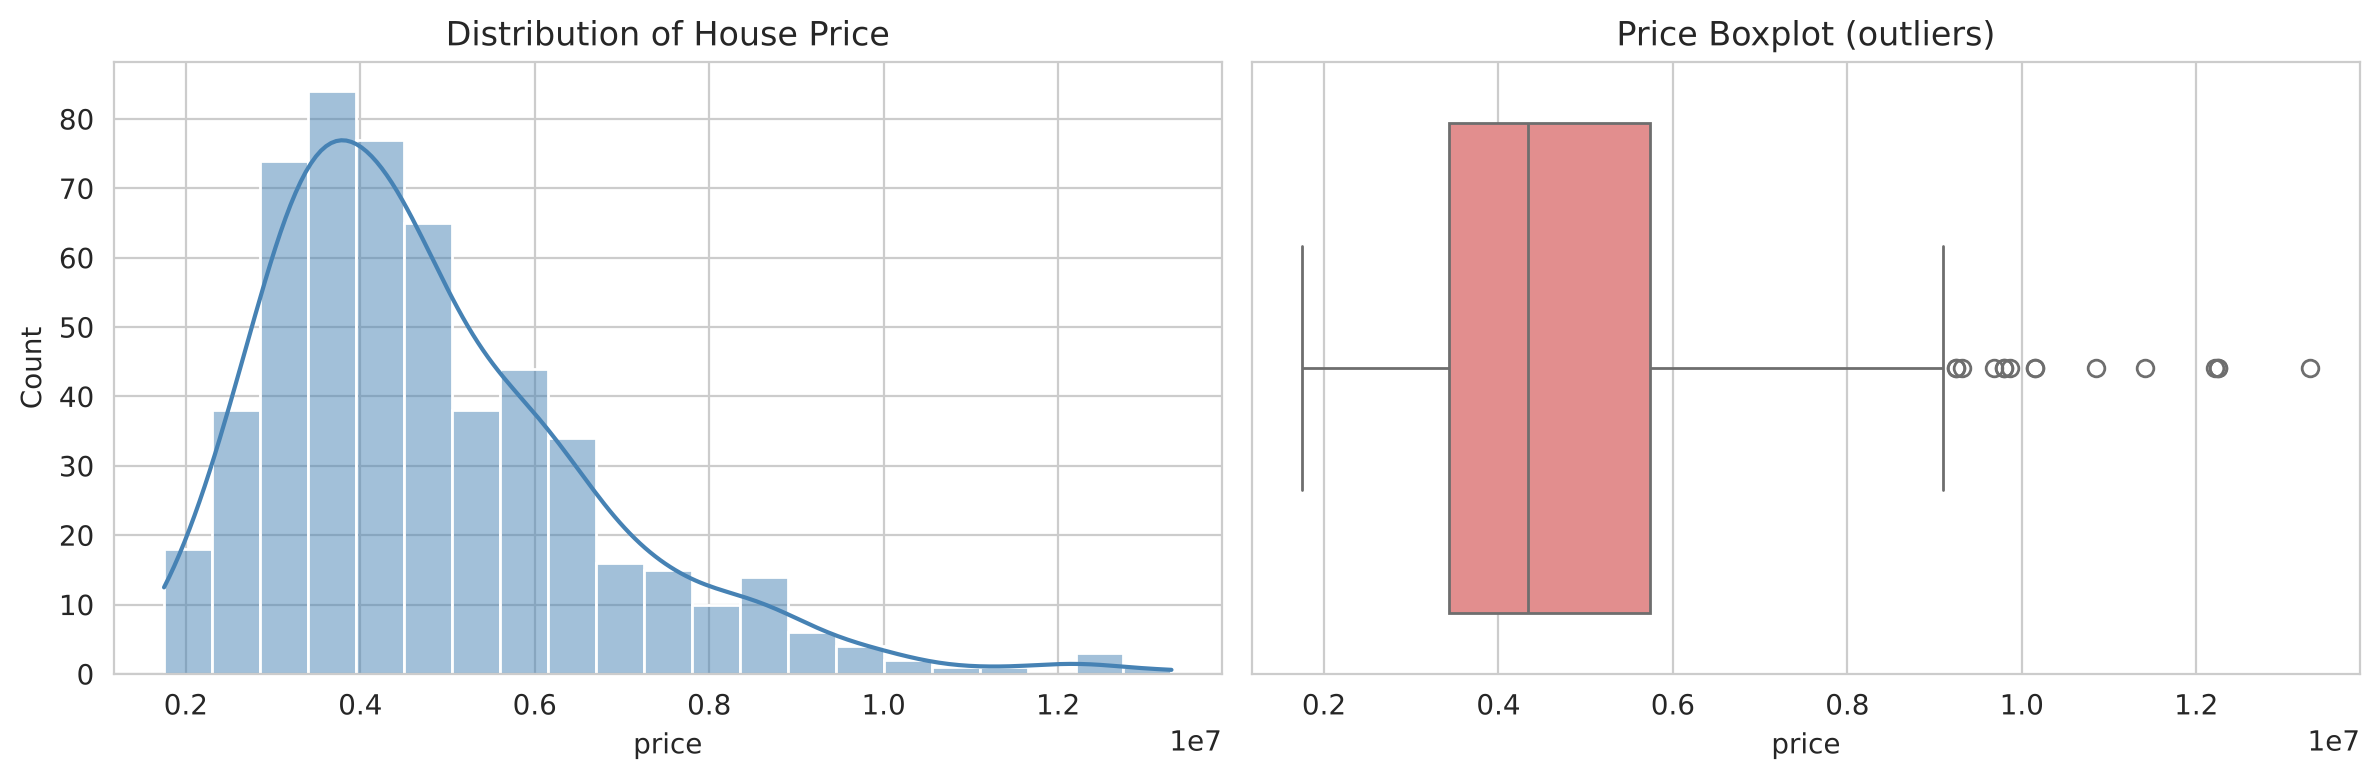

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of House Price")
sns.boxplot(x=df["price"], ax=axes[1], color="lightcoral")
axes[1].set_title("Price Boxplot (outliers)")
plt.tight_layout()
plt.show()

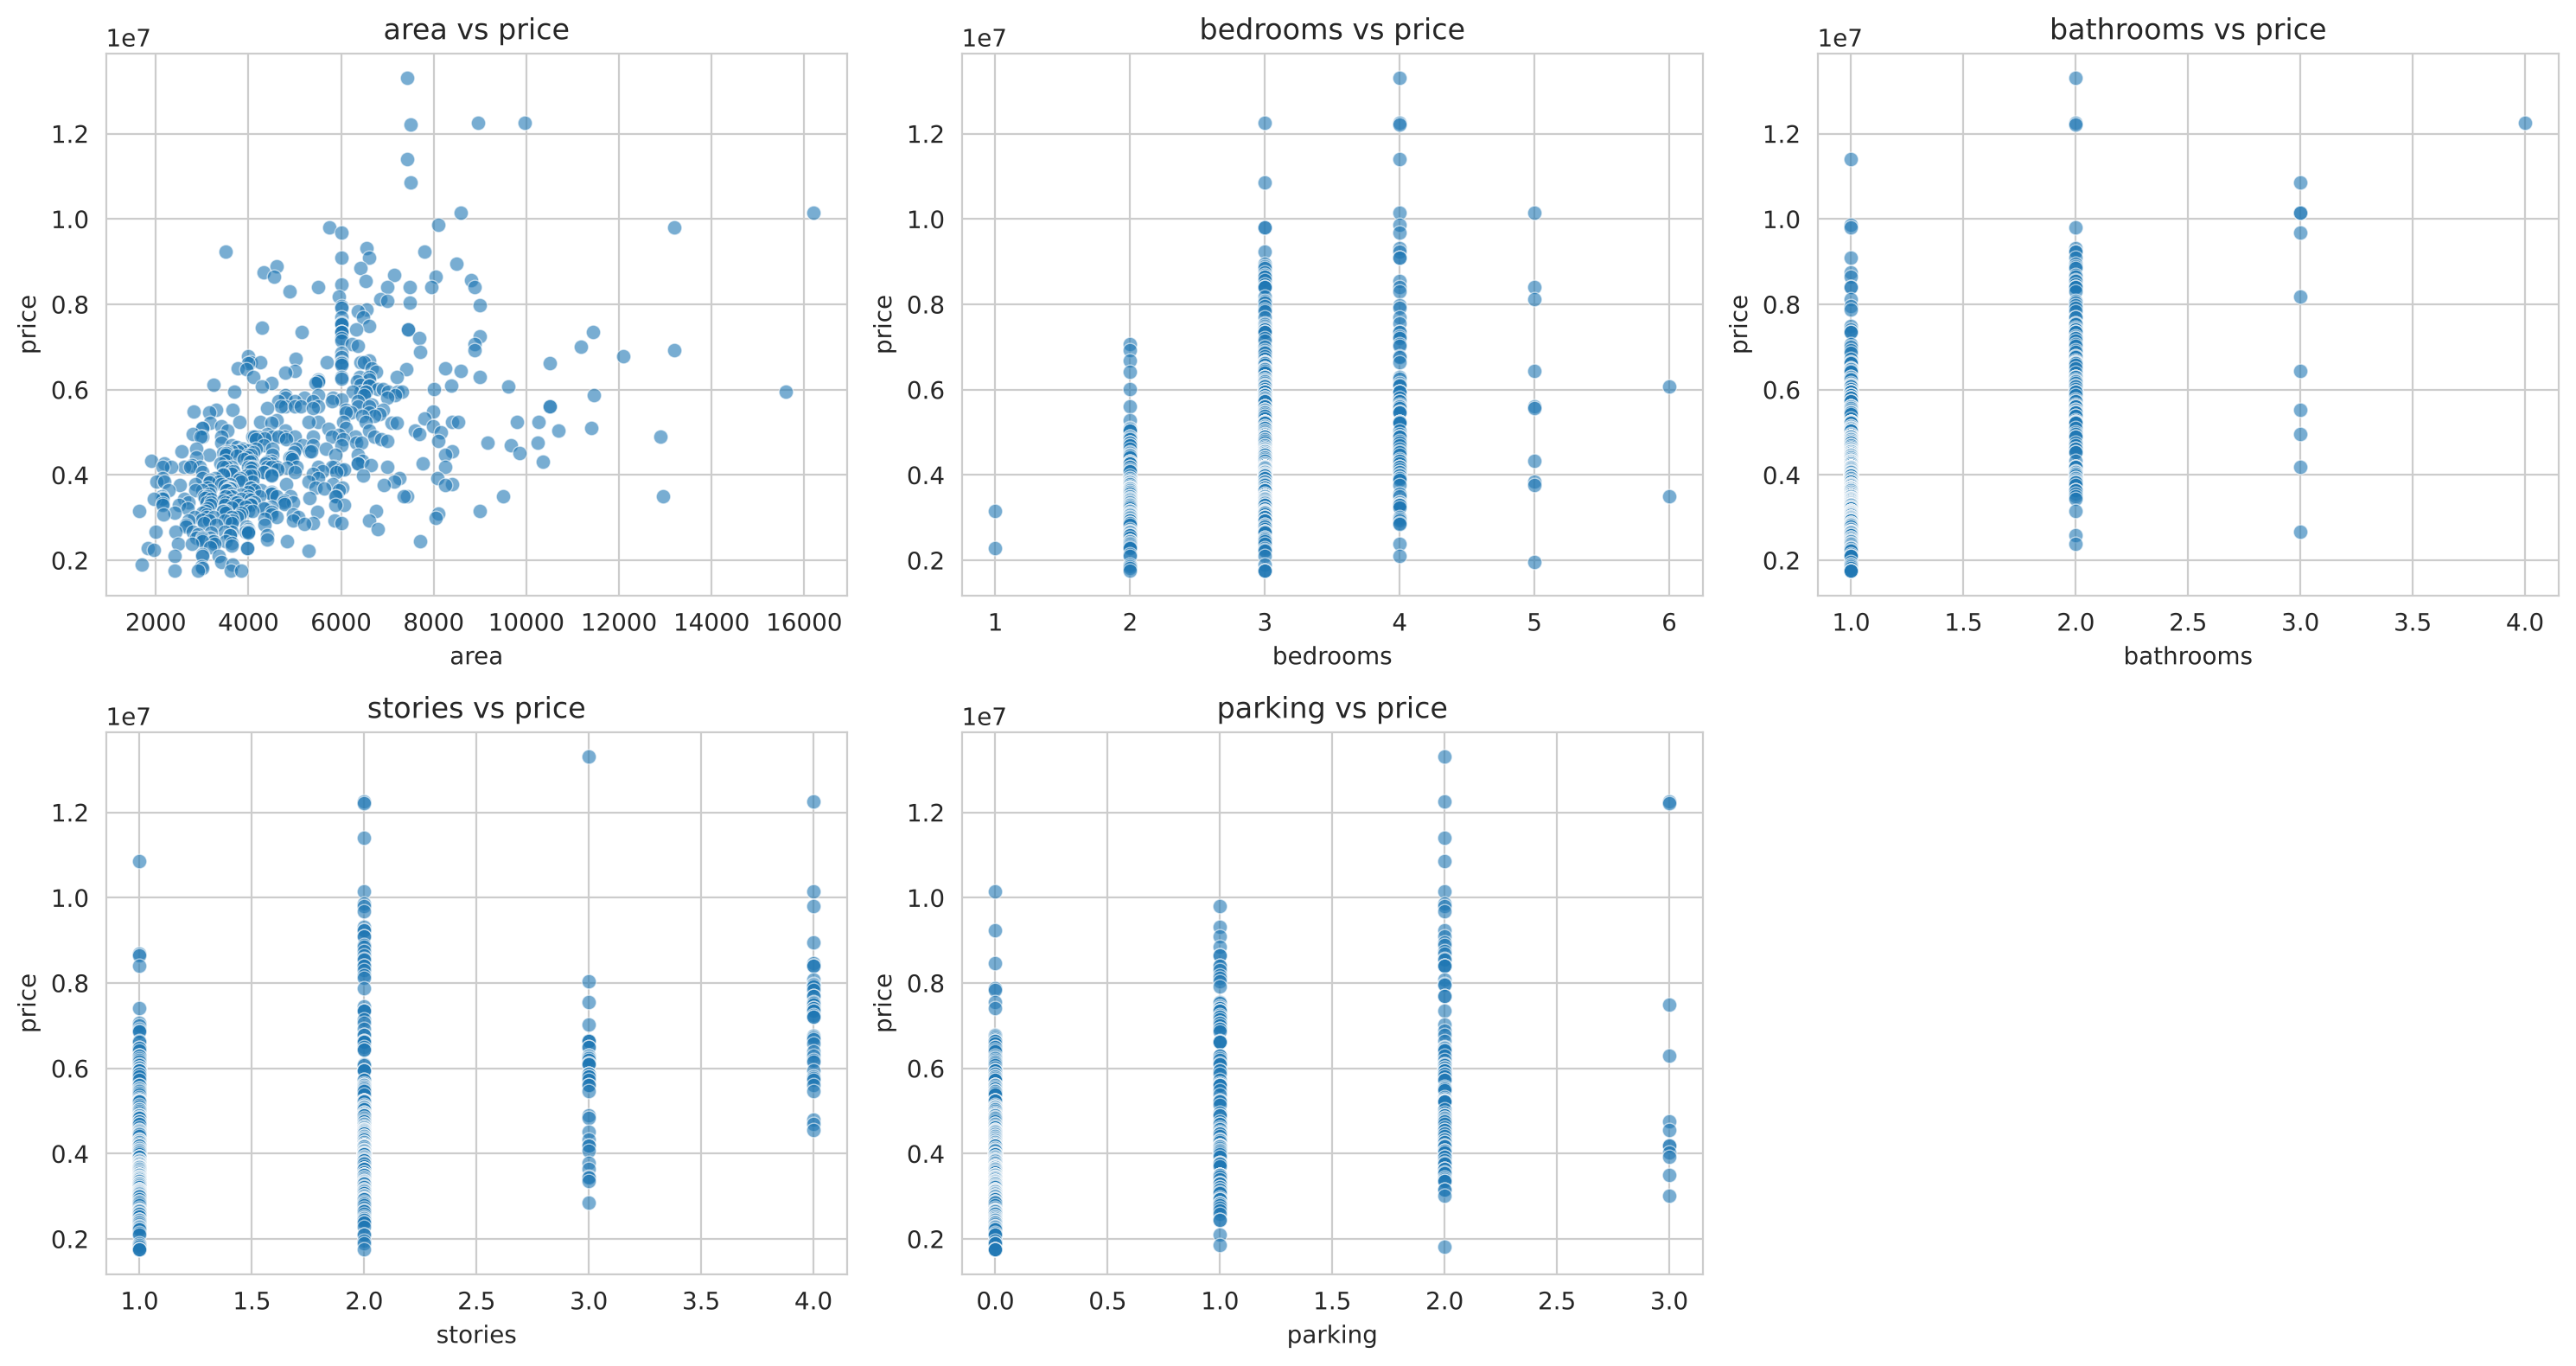

In [6]:
num_cols = ["area", "bedrooms", "bathrooms", "stories", "parking"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.scatterplot(x=df[col], y=df["price"], ax=ax, alpha=0.6)
    ax.set_title(f"{col} vs price")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

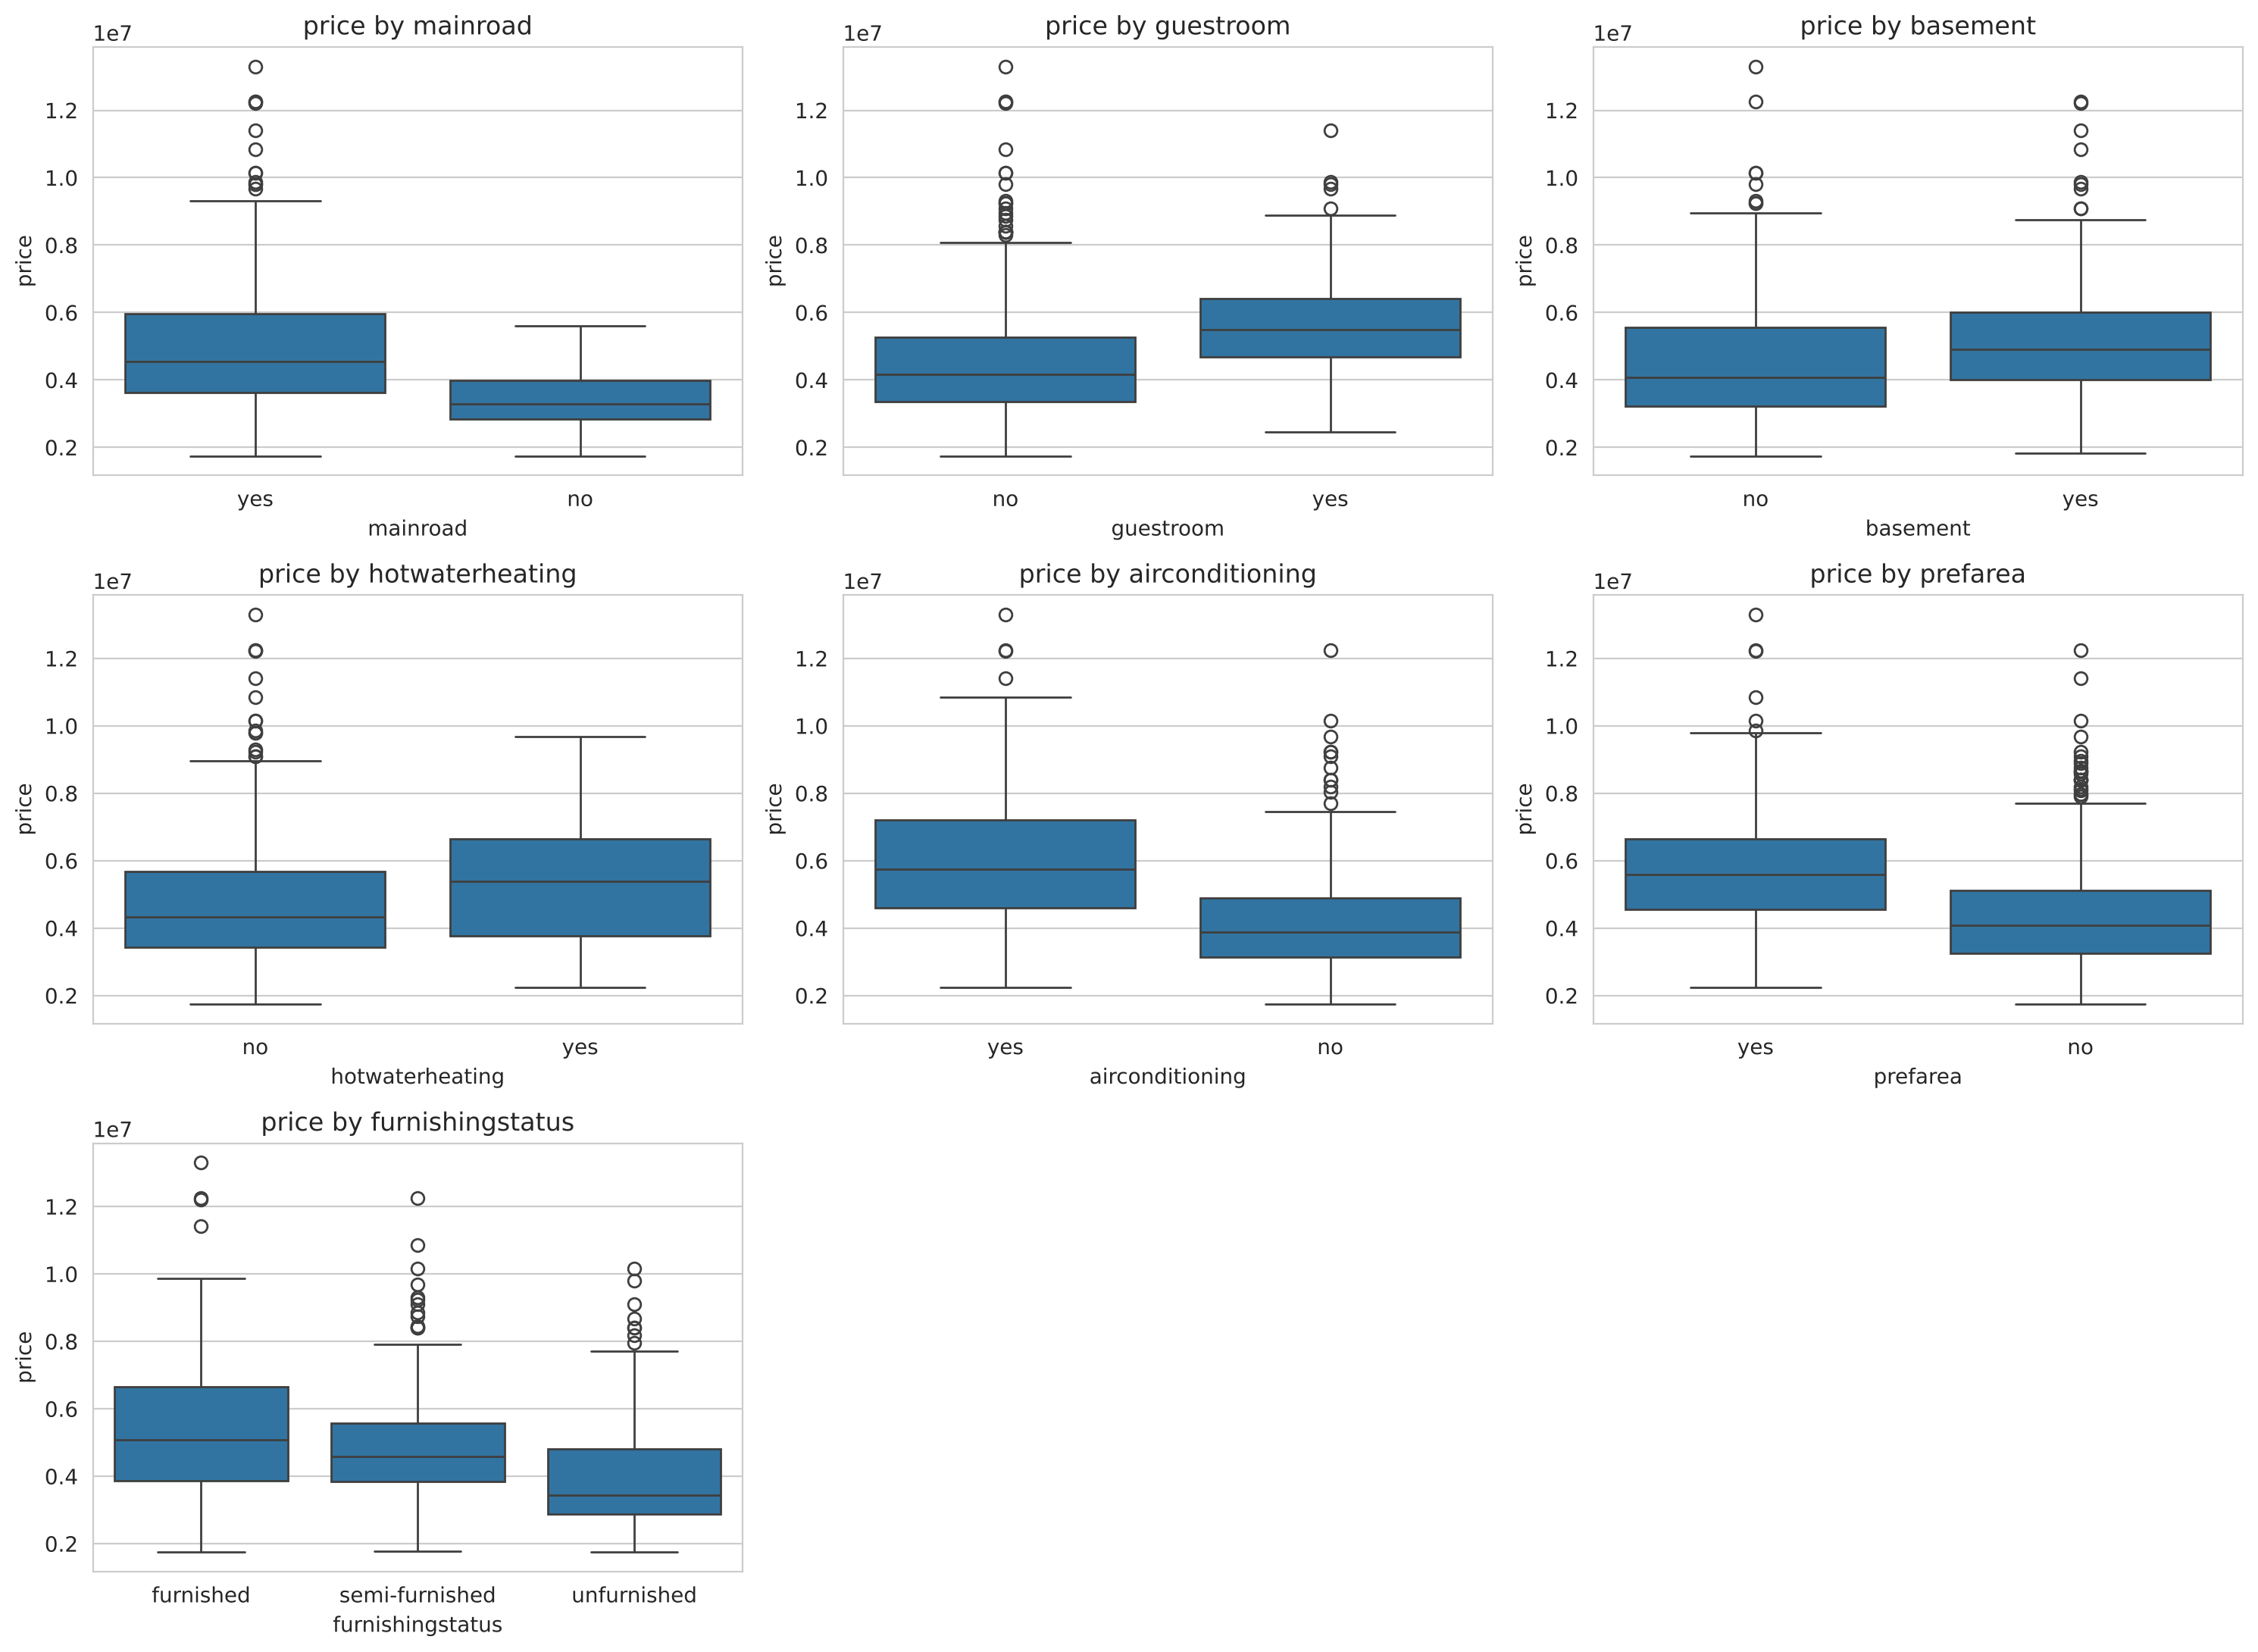

In [7]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.boxplot(x=df[col], y=df["price"], ax=ax)
    ax.set_title(f"price by {col}")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Data Preprocessing
Binary `yes/no` columns → 1/0. `furnishingstatus` (3 categories) → one-hot encoding (`drop_first=True` to avoid the dummy-variable trap).

In [8]:
data = df.copy()

binary_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
for col in binary_cols:
    data[col] = data[col].map({"yes": 1, "no": 0})

data = pd.get_dummies(data, columns=["furnishingstatus"], drop_first=True, dtype=int)
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


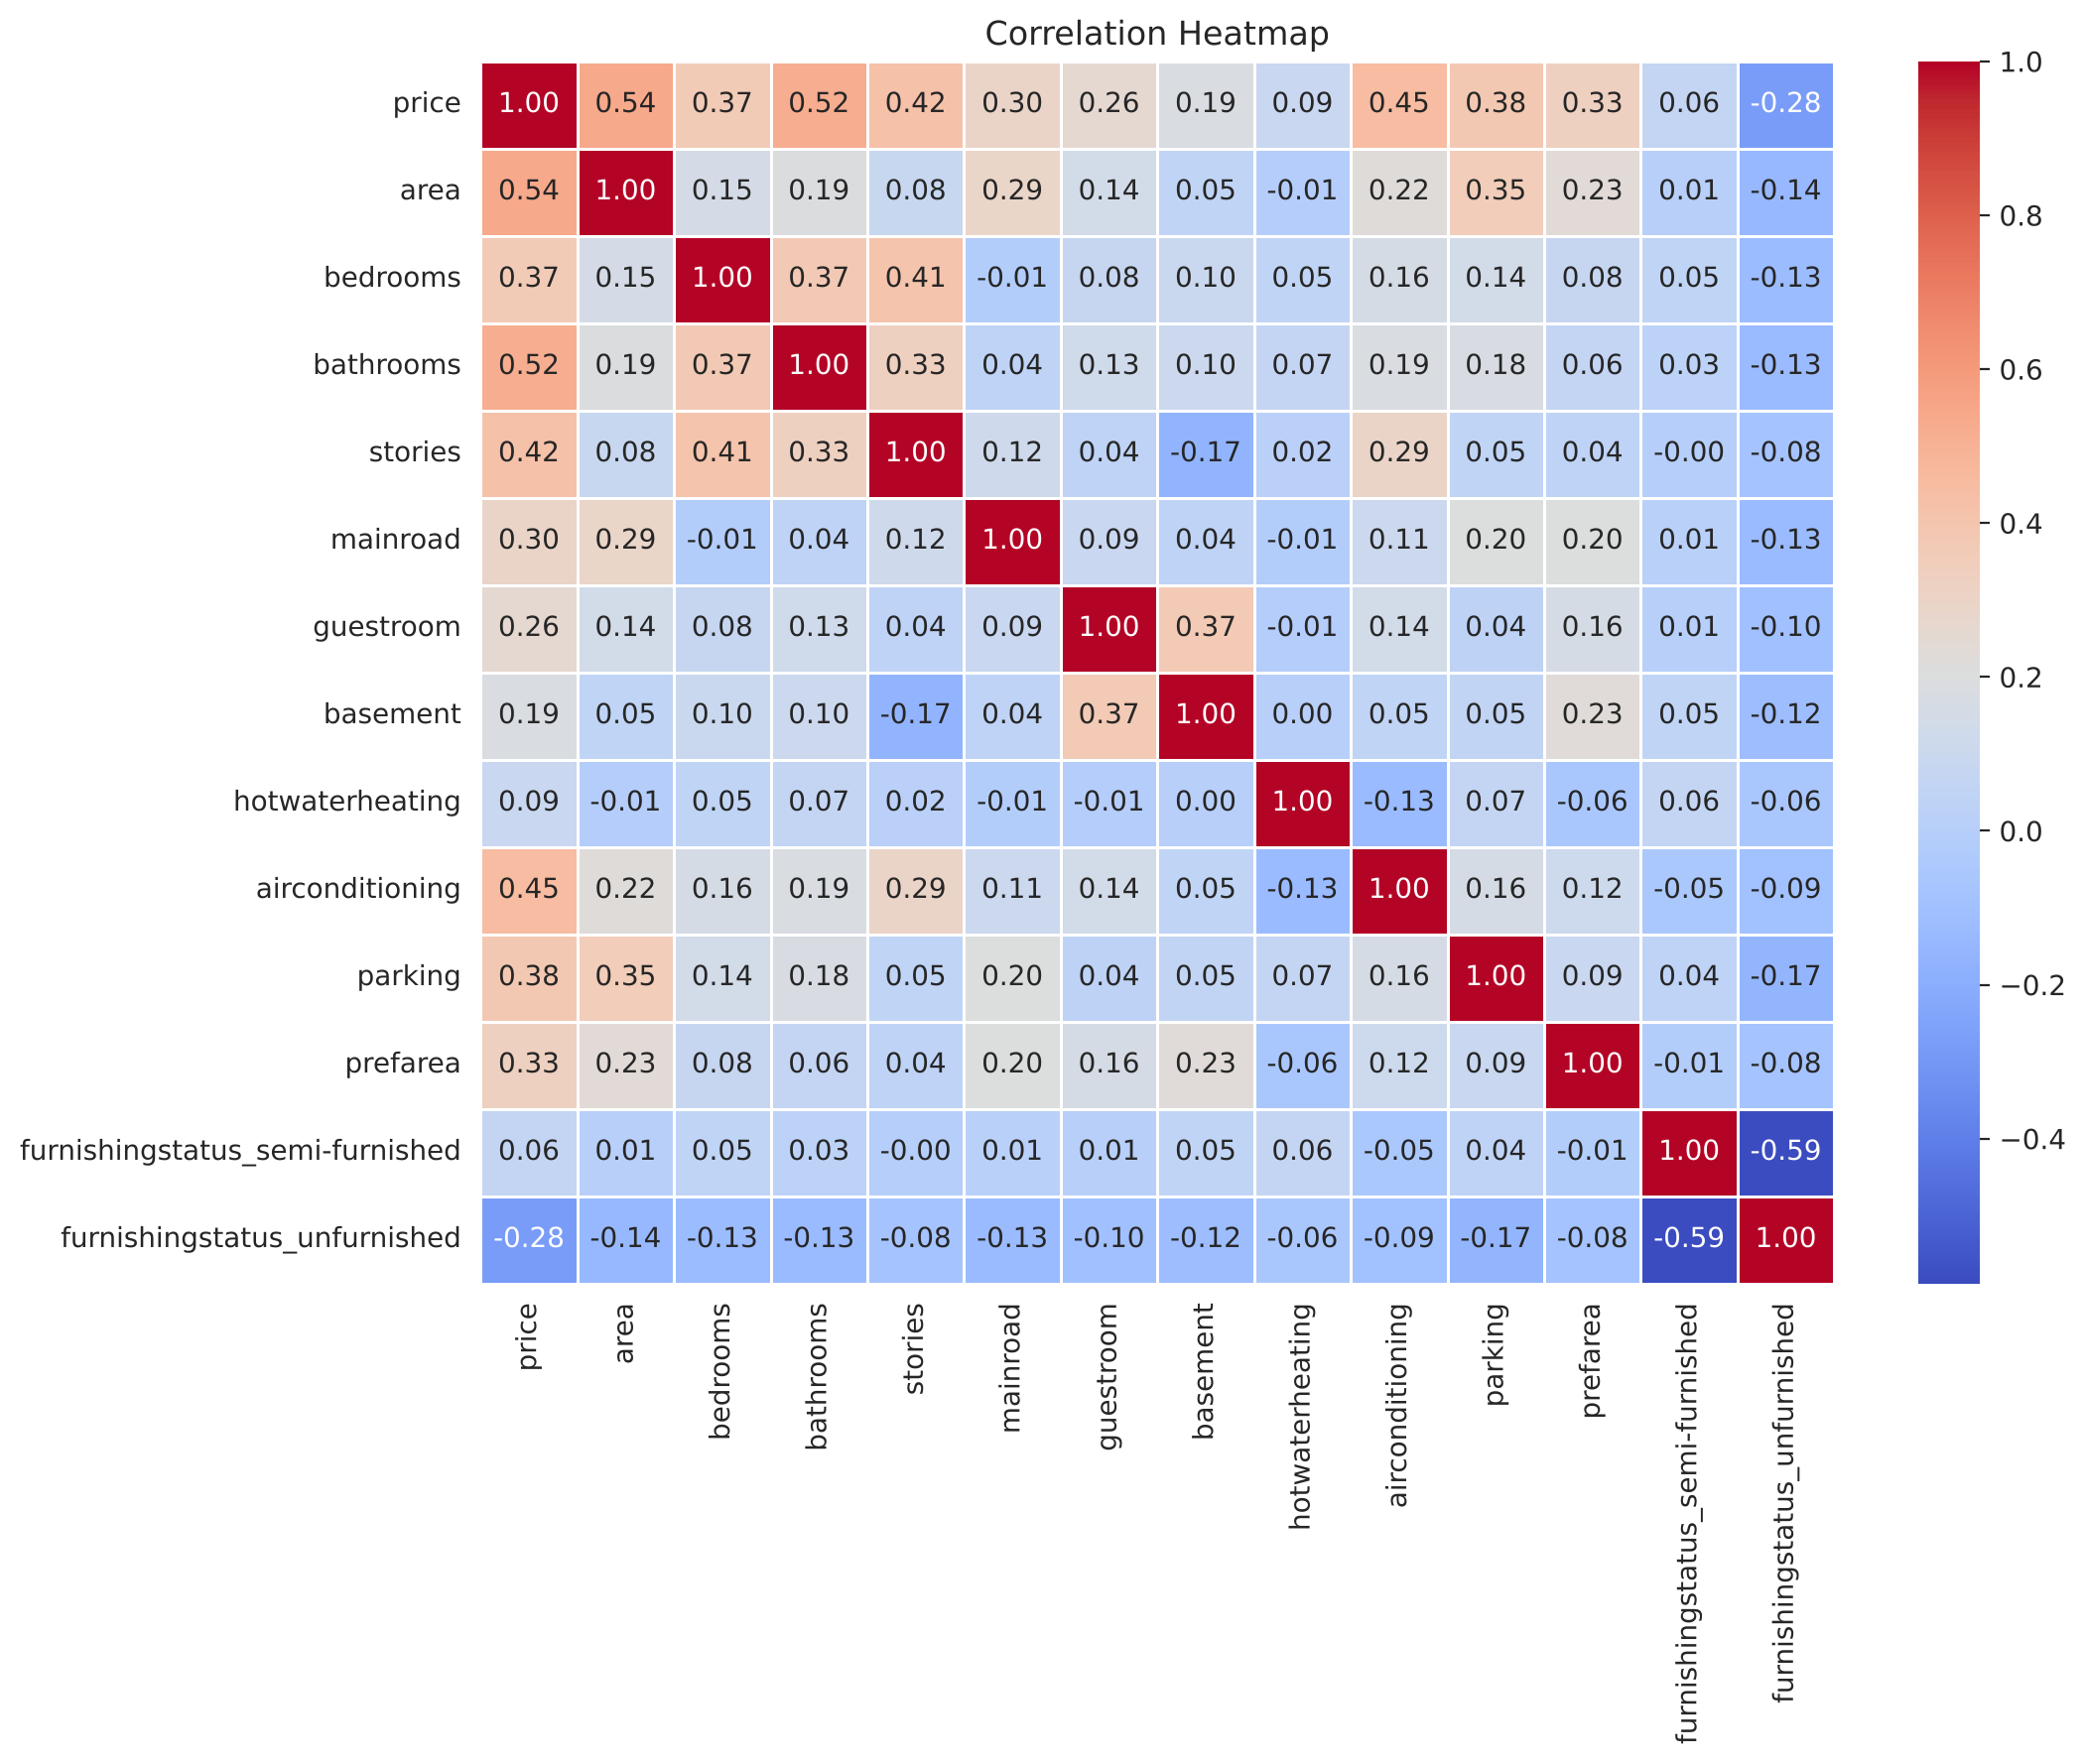

Correlation with price:
area                               0.535997
bathrooms                          0.517545
airconditioning                    0.452954
stories                            0.420712
parking                            0.384394
bedrooms                           0.366494
prefarea                           0.329777
mainroad                           0.296898
guestroom                          0.255517
basement                           0.187057
hotwaterheating                    0.093073
furnishingstatus_semi-furnished    0.063656
furnishingstatus_unfurnished      -0.280587
Name: price, dtype: float64


In [9]:
plt.figure(figsize=(11, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with price:")
print(data.corr()["price"].sort_values(ascending=False).drop("price"))

## 5. Train–Test Split (80% / 20%)

In [10]:
X = data.drop("price", axis=1)
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (436, 13) | Test: (109, 13)


## 6. Train the Linear Regression Model
(Feature scaling is not required for plain Linear Regression – predictions are unaffected, and unscaled coefficients stay easy to interpret.)

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model trained ✔")
print("Intercept:", round(model.intercept_, 2))

Model trained ✔
Intercept: 260032.36


## 7. Predict House Prices

In [12]:
y_pred_train = model.predict(X_train)
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.round(0),
})
results["Error"] = results["Actual"] - results["Predicted"]
results.head(10)

,Actual,Predicted,Error
0,4060000,5164654.0,-1104654.0
1,6650000,7224722.0,-574722.0
2,3710000,3109863.0,600137.0
3,6440000,4612075.0,1827925.0
4,2800000,3294646.0,-494646.0
5,4900000,3532275.0,1367725.0
6,5250000,5611775.0,-361775.0
7,4543000,6368146.0,-1825146.0
8,2450000,2722857.0,-272857.0
9,3353000,2629406.0,723594.0


## 8. Model Evaluation (MSE, RMSE, MAE, R²)

In [13]:
def evaluate(y_true, y_hat, name):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "Set": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_hat),
        "R² Score": r2_score(y_true, y_hat),
    }

metrics = pd.DataFrame([
    evaluate(y_train, y_pred_train, "Train"),
    evaluate(y_test, y_pred, "Test"),
]).set_index("Set")
metrics.style.format({"MSE": "{:,.0f}", "RMSE": "{:,.0f}", "MAE": "{:,.0f}", "R² Score": "{:.4f}"})

,MSE,RMSE,MAE,R² Score
Set,,,,
Train,"968,358,188,441","984,052","719,243",0.6859
Test,"1,754,318,687,331","1,324,507","970,043",0.6529


In [14]:
r2 = r2_score(y_test, y_pred)
print(f"Test R² Score : {r2:.4f}  → model explains {r2*100:.1f}% of the variance in house prices")
print(f"Test RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred)):,.0f}  (typical prediction error)")
print(f"Test MAE      : {mean_absolute_error(y_test, y_pred):,.0f}")

Test R² Score : 0.6529  → model explains 65.3% of the variance in house prices
Test RMSE     : 1,324,507  (typical prediction error)
Test MAE      : 970,043


## 9. Plot: Predicted vs. Actual Prices
Points close to the red dashed line (perfect prediction) mean accurate predictions.

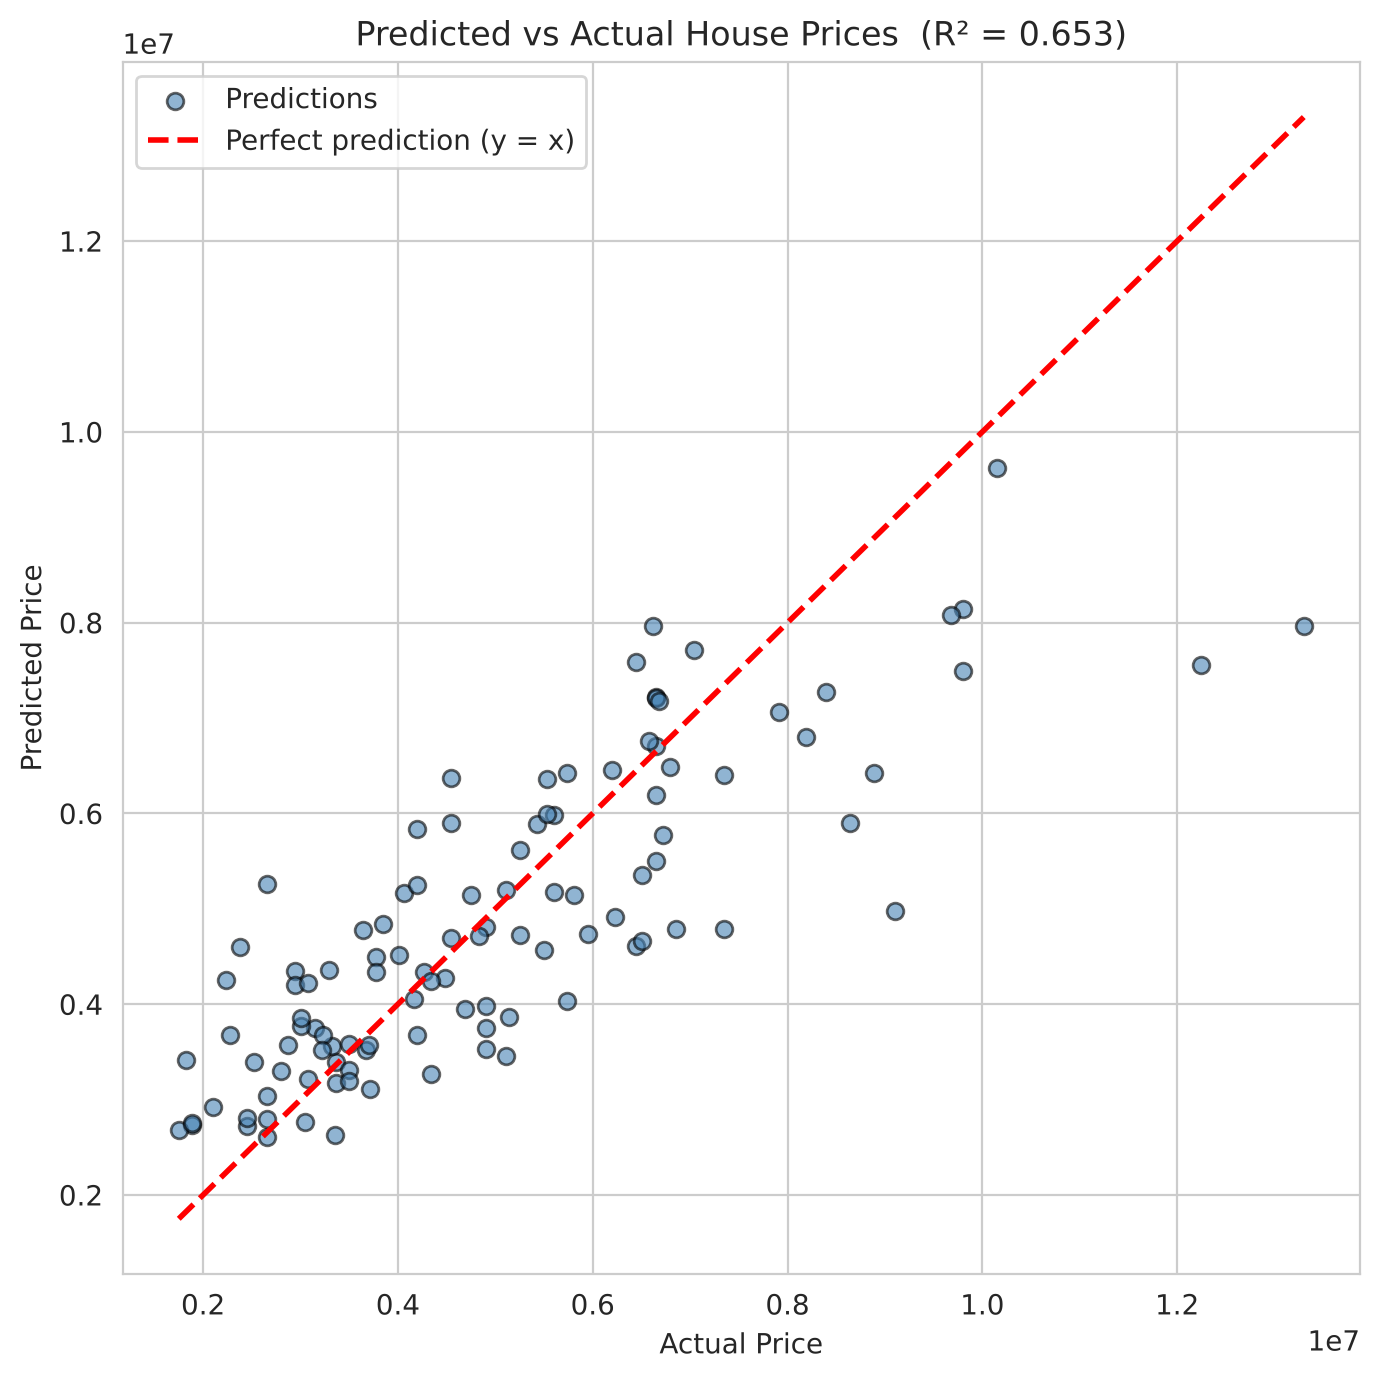

In [15]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6, color="steelblue", edgecolor="k", label="Predictions")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", lw=2, label="Perfect prediction (y = x)")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Predicted vs Actual House Prices  (R² = {r2:.3f})")
plt.legend()
plt.tight_layout()
plt.show()

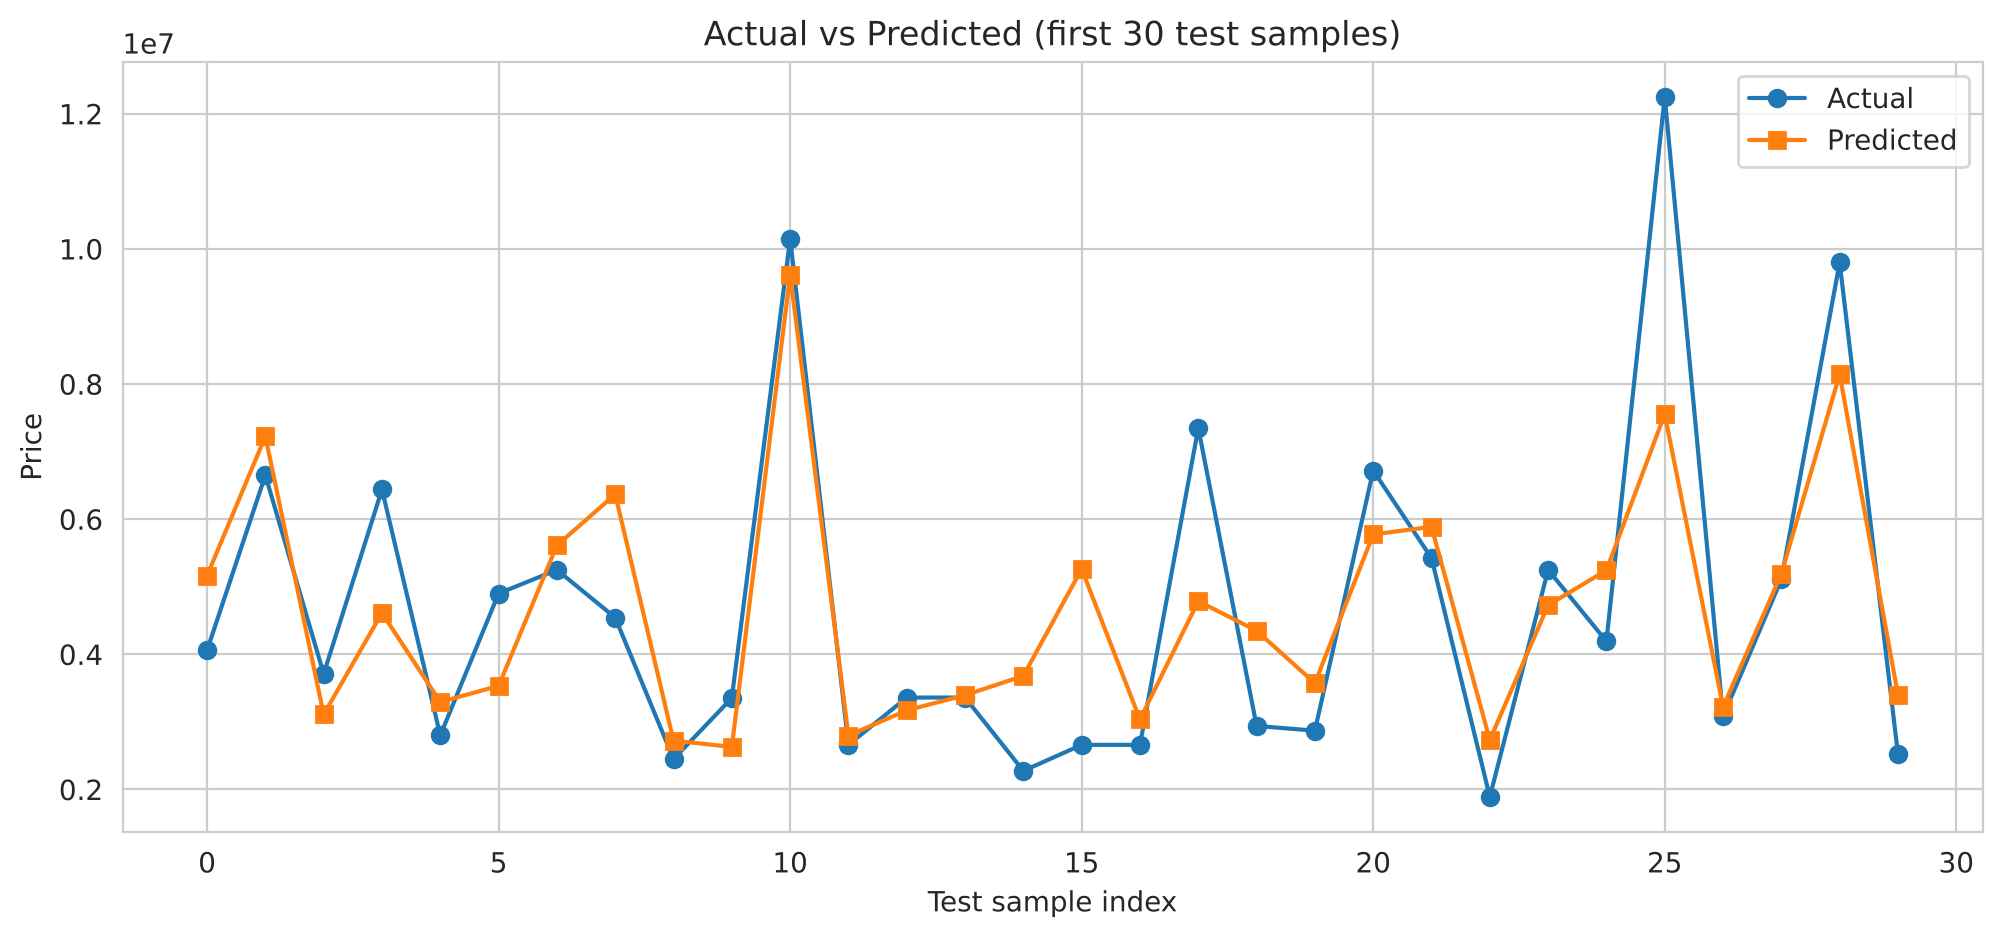

In [16]:
# Side-by-side comparison for the first 30 test houses
n = 30
plt.figure(figsize=(12, 5))
plt.plot(range(n), y_test.values[:n], marker="o", label="Actual")
plt.plot(range(n), y_pred[:n], marker="s", label="Predicted")
plt.xlabel("Test sample index")
plt.ylabel("Price")
plt.title("Actual vs Predicted (first 30 test samples)")
plt.legend()
plt.show()

## 10. Residual Analysis
For a good linear model, residuals should be centred around 0 with no strong pattern.

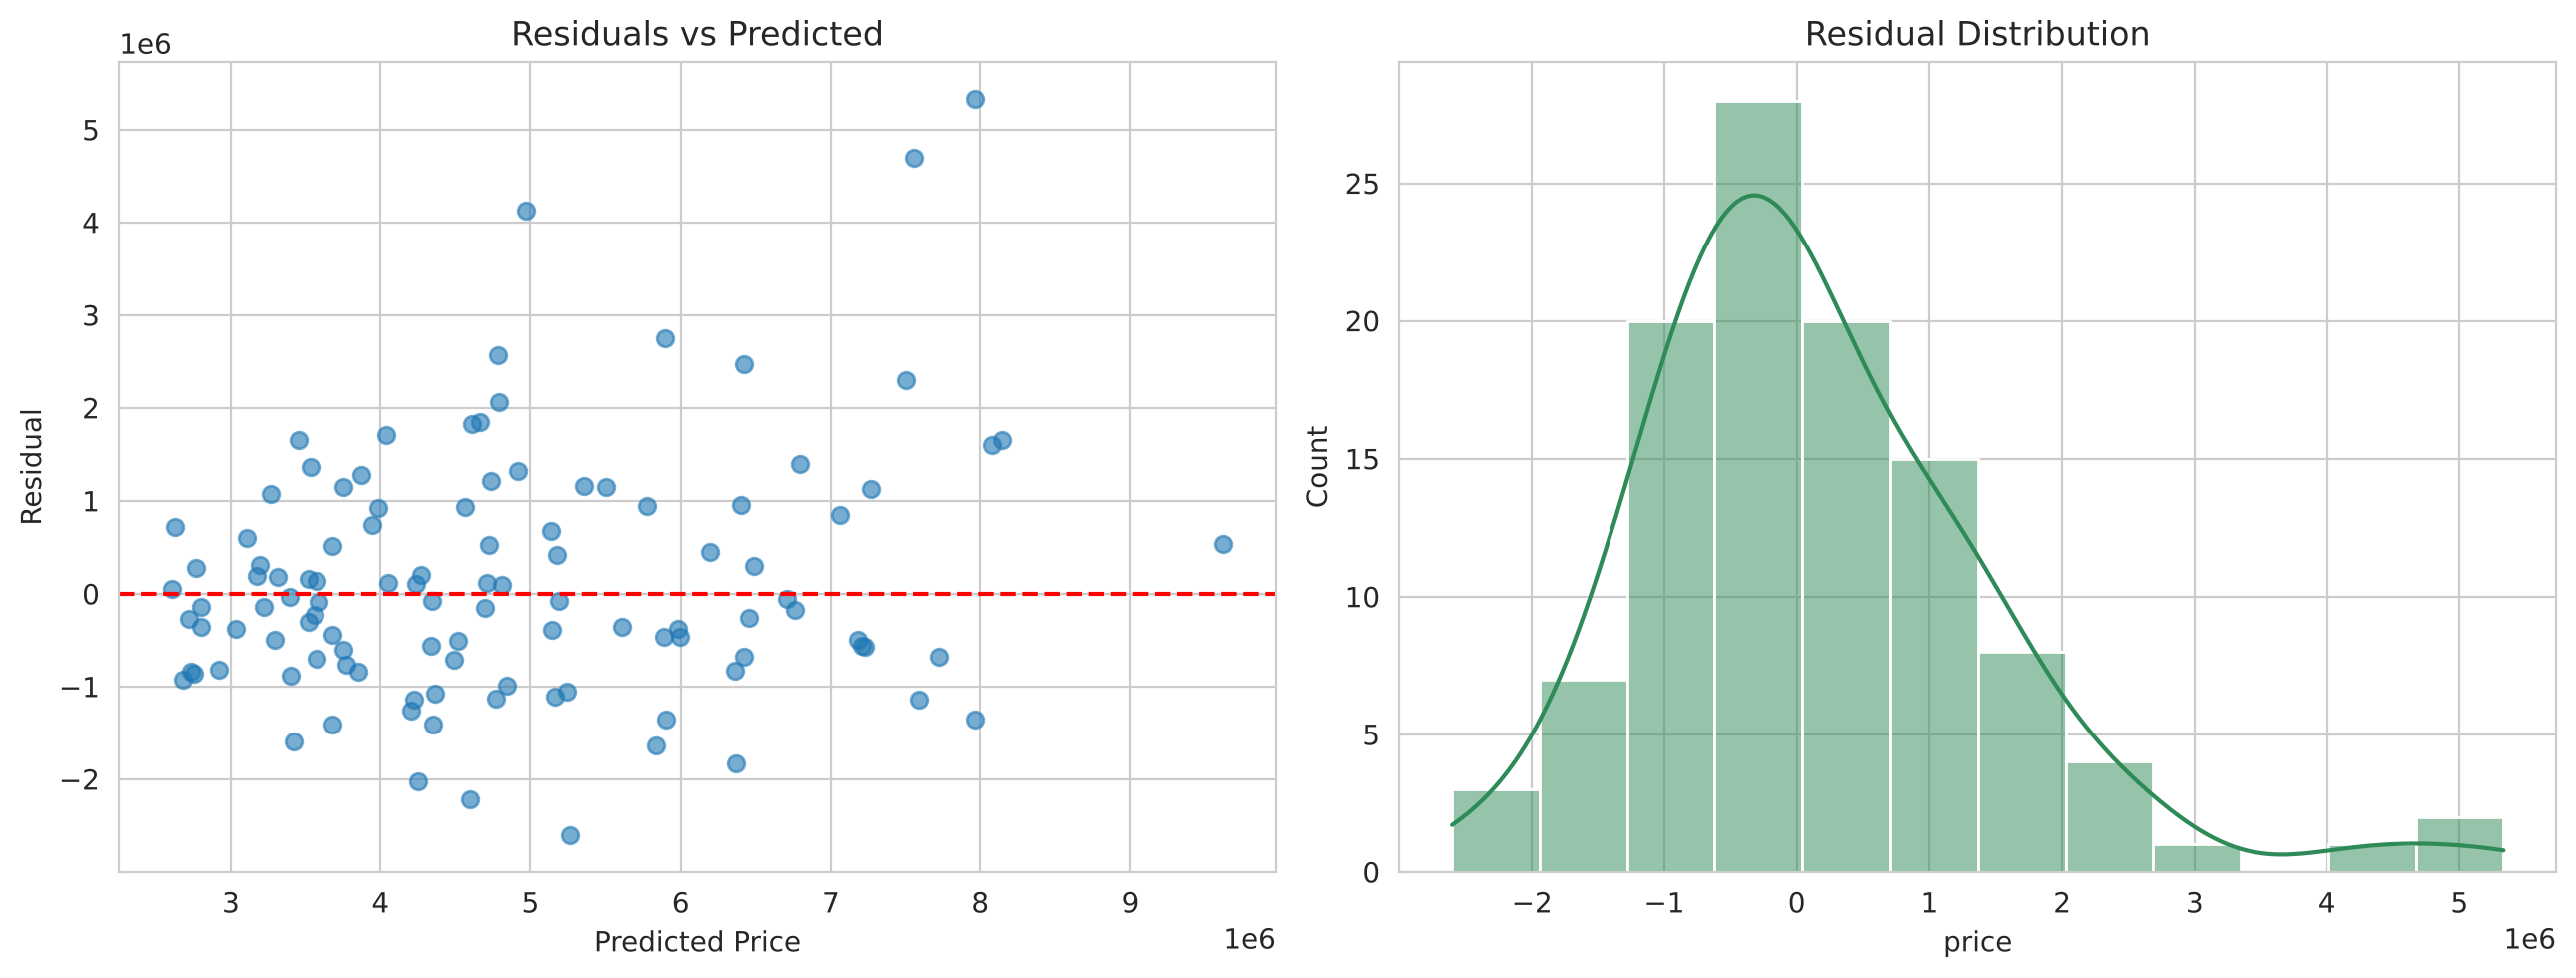

In [17]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color="r", ls="--")
axes[0].set_xlabel("Predicted Price"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

## 11. Feature Importance (Model Coefficients)
Each coefficient is the change in price for a 1-unit increase in that feature, holding the others constant.

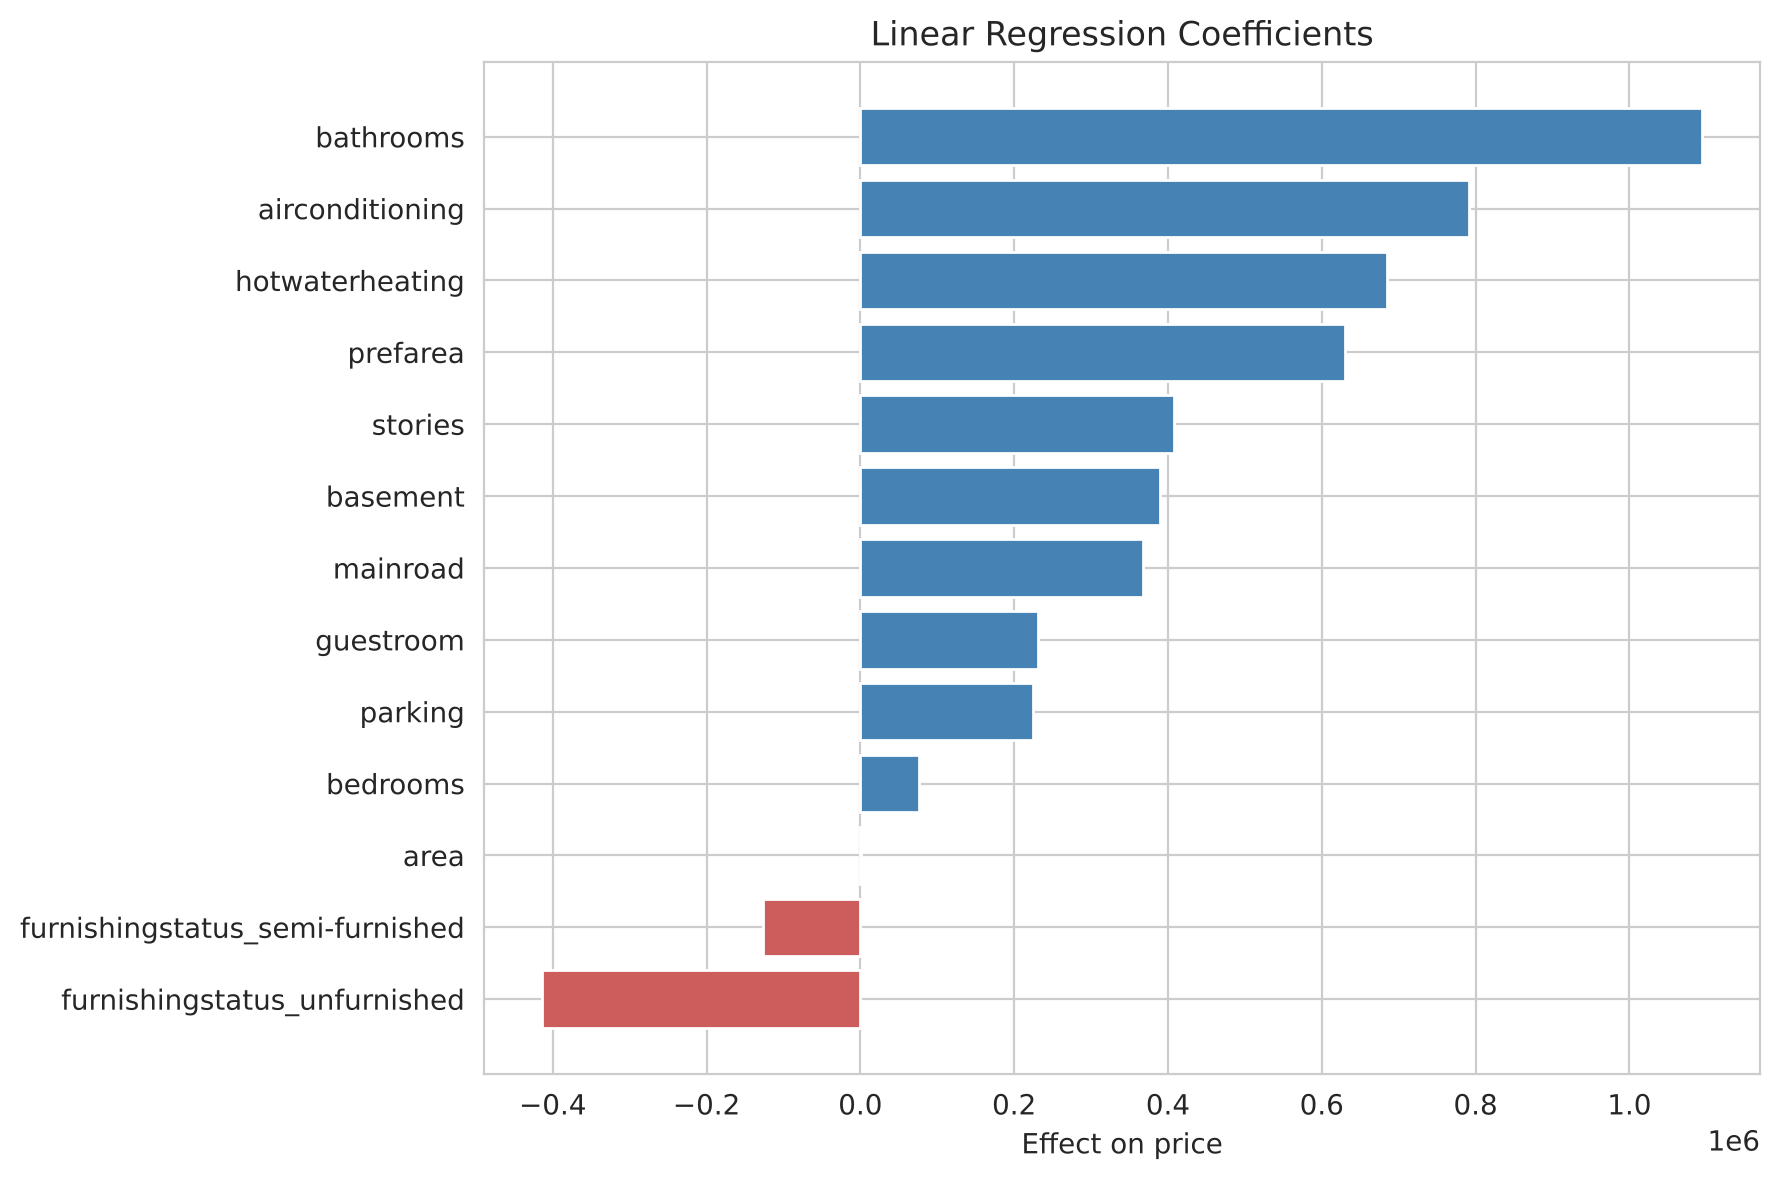

,Feature,Coefficient
0,bathrooms,1.094445e+06
1,airconditioning,7.914267e+05
2,hotwaterheating,6.846499e+05
3,prefarea,6.298906e+05
4,stories,4.074766e+05
5,basement,3.902512e+05
6,mainroad,3.679199e+05
7,guestroom,2.316100e+05
8,parking,2.248419e+05
9,bedrooms,7.677870e+04


In [18]:
coef = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_}).sort_values("Coefficient")

plt.figure(figsize=(9, 6))
colors = ["indianred" if c < 0 else "steelblue" for c in coef["Coefficient"]]
plt.barh(coef["Feature"], coef["Coefficient"], color=colors)
plt.title("Linear Regression Coefficients")
plt.xlabel("Effect on price")
plt.tight_layout()
plt.show()

coef.sort_values("Coefficient", ascending=False).reset_index(drop=True)

## 12. 5-Fold Cross-Validation
Checks that the R² score is stable and not just a lucky train/test split. (`shuffle=True` is essential here because the dataset is sorted by price.)

In [19]:
# NOTE: the CSV is sorted by price, so folds MUST be shuffled
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
print("R² per fold:", cv_scores.round(4))
print(f"Mean R²: {cv_scores.mean():.4f}  (± {cv_scores.std():.4f})")

R² per fold: [0.6529 0.7121 0.4928 0.658  0.6464]
Mean R²: 0.6324  (± 0.0737)


## 13. Predict the Price of a New House

In [20]:
new_house = pd.DataFrame([{
    "area": 6000, "bedrooms": 3, "bathrooms": 2, "stories": 2,
    "mainroad": 1, "guestroom": 0, "basement": 1, "hotwaterheating": 0,
    "airconditioning": 1, "parking": 2, "prefarea": 1,
    "furnishingstatus_semi-furnished": 1, "furnishingstatus_unfurnished": 0,
}])[X.columns]

print(f"Predicted price: {model.predict(new_house)[0]:,.0f}")

Predicted price: 7,412,314


## 14. Conclusion
- A **Linear Regression** model was trained on 80% of the data and tested on the unseen 20%.
- Performance is reported using **R², MSE, RMSE and MAE** (see Section 8). The test R² shows how much of the price variation the model explains.
- **Predicted vs. actual** points cluster around the diagonal, but spread out at higher prices – the model under-predicts expensive houses.
- **Bathrooms, air conditioning, hot-water heating, preferred area and stories** have the largest positive coefficients; **unfurnished** houses are priced lower. `area` has a small raw coefficient only because its scale is large (thousands of sq. ft) – it is still one of the strongest correlates of price.
- Cross-validation confirms the score is reasonably stable.

**Possible improvements:** log-transform `price`, add polynomial/interaction features, remove outliers, regularization (Ridge/Lasso), or try Random Forest / Gradient Boosting.